In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

price_files = {
    -2: "../data/prices_round_1_day_-2.csv",
    -1: "../data/prices_round_1_day_-1.csv",
    0: "../data/prices_round_1_day_0.csv",
}

trade_files = {
    -2: "../data/trades_round_1_day_-2.csv",
    -1: "../data/trades_round_1_day_-1.csv",
    0: "../data/trades_round_1_day_0.csv",
}

price_frames = []
trade_frames = []

for day, path in price_files.items():
    frame = pd.read_csv(path, sep=";")
    frame["day"] = day
    price_frames.append(frame)

for day, path in trade_files.items():
    frame = pd.read_csv(path, sep=";")
    frame["day"] = day
    trade_frames.append(frame)

prices = pd.concat(price_frames, ignore_index=True).sort_values(["day", "timestamp"]).reset_index(drop=True)
trades = pd.concat(trade_frames, ignore_index=True).sort_values(["day", "timestamp"]).reset_index(drop=True)

def prepare_product_context(product: str):
    price_cols = [
        "day",
        "timestamp",
        "product",
        "bid_price_1",
        "bid_volume_1",
        "ask_price_1",
        "ask_volume_1",
        "mid_price",
        "profit_and_loss",
    ]
    price_cols = [col for col in price_cols if col in prices.columns]

    price_prod = prices.loc[prices["product"] == product, price_cols].copy().sort_values(["day", "timestamp"])
    price_prod = price_prod[price_prod["mid_price"] > 0].copy()
    if {"bid_price_1", "ask_price_1"}.issubset(price_prod.columns):
        price_prod["spread_1"] = price_prod["ask_price_1"] - price_prod["bid_price_1"]
    else:
        price_prod["spread_1"] = np.nan
    price_prod["mid_change_1"] = price_prod.groupby("day")["mid_price"].shift(-1) - price_prod["mid_price"]
    price_prod["mid_change_5"] = price_prod.groupby("day")["mid_price"].shift(-5) - price_prod["mid_price"]
    price_prod["return_1"] = price_prod.groupby("day")["mid_price"].pct_change()

    trade_prod = trades.loc[trades["symbol"] == product, ["day", "timestamp", "price", "quantity"]].copy().sort_values(["day", "timestamp"])
    merged_frames = []
    for day in sorted(trade_prod["day"].dropna().unique().tolist()):
        trade_day = trade_prod[trade_prod["day"] == day].sort_values("timestamp")
        price_day = price_prod[price_prod["day"] == day].drop(columns=["day"]).sort_values("timestamp")
        if trade_day.empty or price_day.empty:
            continue
        merged_day = pd.merge_asof(
            trade_day,
            price_day,
            on="timestamp",
            direction="backward",
        )
        merged_frames.append(merged_day)

    trade_ctx = pd.concat(merged_frames, ignore_index=True) if merged_frames else trade_prod.copy()
    if "mid_price" not in trade_ctx.columns:
        for col in ["mid_price", "spread_1", "mid_change_1", "mid_change_5", "return_1"]:
            trade_ctx[col] = np.nan

    trade_ctx["slippage_vs_mid"] = trade_ctx["price"] - trade_ctx["mid_price"]
    trade_ctx["abs_slippage"] = trade_ctx["slippage_vs_mid"].abs()
    trade_ctx["trade_side_est"] = np.where(
        trade_ctx["slippage_vs_mid"] > 0,
        "buy_aggressive",
        np.where(trade_ctx["slippage_vs_mid"] < 0, "sell_aggressive", "at_mid"),
    )
    trade_ctx["realized_edge_1"] = np.where(
        trade_ctx["trade_side_est"] == "buy_aggressive",
        trade_ctx["mid_change_1"] - trade_ctx["slippage_vs_mid"],
        np.where(
            trade_ctx["trade_side_est"] == "sell_aggressive",
            -trade_ctx["mid_change_1"] + trade_ctx["slippage_vs_mid"],
            np.nan,
        ),
    )
    trade_ctx["time_bucket"] = pd.qcut(trade_ctx["timestamp"], q=4, labels=False, duplicates="drop")

    return price_prod, trade_ctx

ash_price_prod, ash_trade_ctx = prepare_product_context("ASH_COATED_OSMIUM")
pepper_price_prod, pepper_trade_ctx = prepare_product_context("INTARIAN_PEPPER_ROOT")

In [15]:
ash_price_summary = ash_price_prod.groupby("day").agg(
    trade_count=("mid_price", "count"),
    mid_mean=("mid_price", "mean"),
    mid_median=("mid_price", "median"),
    mid_std=("mid_price", "std"),
    spread_mean=("spread_1", "mean"),
    spread_p90=("spread_1", lambda s: s.quantile(0.90)),
    return_autocorr_lag1=("return_1", lambda s: s.autocorr(lag=1)),
    return_autocorr_lag5=("return_1", lambda s: s.autocorr(lag=5)),
    avg_bid_vol_1=("bid_volume_1", "mean"),
    avg_ask_vol_1=("ask_volume_1", "mean"),
).reset_index()

ash_trade_summary = ash_trade_ctx.groupby("day").agg(
    trade_count=("price", "count"),
    total_quantity=("quantity", "sum"),
    abs_quantity=("quantity", lambda s: s.abs().sum()),
    vwap=("price", lambda s: np.average(s, weights=ash_trade_ctx.loc[s.index, "quantity"].abs())),
    trade_price_mean=("price", "mean"),
    trade_price_std=("price", "std"),
    slippage_mean=("slippage_vs_mid", "mean"),
    slippage_median=("slippage_vs_mid", "median"),
    abs_slippage_mean=("abs_slippage", "mean"),
    realized_edge_mean=("realized_edge_1", "mean"),
    realized_edge_median=("realized_edge_1", "median"),
).reset_index()

ash_side_summary = ash_trade_ctx.groupby(["day", "trade_side_est"]).agg(
    trade_count=("price", "count"),
    quantity_sum=("quantity", "sum"),
    price_mean=("price", "mean"),
    slippage_mean=("slippage_vs_mid", "mean"),
    abs_slippage_mean=("abs_slippage", "mean"),
    realized_edge_mean=("realized_edge_1", "mean"),
).reset_index()

ash_time_summary = ash_trade_ctx.groupby(["day", "time_bucket"]).agg(
    trade_count=("price", "count"),
    quantity_sum=("quantity", "sum"),
    price_mean=("price", "mean"),
    mid_mean=("mid_price", "mean"),
    slippage_mean=("slippage_vs_mid", "mean"),
    realized_edge_mean=("realized_edge_1", "mean"),
).reset_index()

ash_slippage_summary = ash_trade_ctx.copy()
ash_slippage_summary["slippage_bucket"] = pd.cut(
    ash_slippage_summary["slippage_vs_mid"],
    bins=[-np.inf, -6, -3, -1, 0, 1, 3, 6, np.inf],
    labels=["<=-6", "-6:-3", "-3:-1", "-1:0", "0:1", "1:3", "3:6", ">=6"],
)

ash_slippage_bucket_summary = ash_slippage_summary.groupby(["day", "slippage_bucket"]).agg(
    trade_count=("price", "count"),
    quantity_sum=("quantity", "sum"),
    price_mean=("price", "mean"),
    mid_mean=("mid_price", "mean"),
    future_move_1_mean=("mid_change_1", "mean"),
    future_move_5_mean=("mid_change_5", "mean"),
    realized_edge_mean=("realized_edge_1", "mean"),
).reset_index()

display(ash_price_summary)
display(ash_trade_summary)
display(ash_side_summary)
display(ash_time_summary)
display(ash_slippage_bucket_summary)

,day,trade_count,mid_mean,mid_median,mid_std,spread_mean,spread_p90,return_autocorr_lag1,return_autocorr_lag5,avg_bid_vol_1,avg_ask_vol_1
0,-2,9982,9998.169906,9998.0,5.219914,16.149777,19.0,-0.500517,-0.003387,14.035465,14.181277
1,-1,9983,10000.833968,10001.0,4.450045,16.191328,19.0,-0.498044,-0.007377,14.173193,14.173329
2,0,9986,10001.608201,10002.0,5.683730,16.184467,19.0,-0.487242,-0.003590,14.156136,14.136822


,day,trade_count,total_quantity,abs_quantity,vwap,trade_price_mean,trade_price_std,slippage_mean,slippage_median,abs_slippage_mean,realized_edge_mean,realized_edge_median
0,-2,429,2210,2210,9998.262896,9998.200466,9.221921,-0.044289,0.0,7.769231,-7.861779,-8.0
1,-1,425,2225,2225,10000.846742,10000.774118,9.102705,-0.020000,0.0,7.963529,-7.786571,-8.0
2,0,411,2158,2158,10001.644578,10001.734793,9.536847,0.502433,3.0,7.835766,-8.171717,-8.0


,day,trade_side_est,trade_count,quantity_sum,price_mean,slippage_mean,abs_slippage_mean,realized_edge_mean
0,-2,at_mid,13,85,9998.000000,0.000000,0.000000,NaN
1,-2,buy_aggressive,206,1050,10006.077670,8.043689,8.043689,-7.961165
2,-2,sell_aggressive,210,1075,9990.485714,-7.980952,7.980952,-7.764286
3,-1,at_mid,8,44,10002.500000,0.000000,0.000000,NaN
4,-1,buy_aggressive,211,1110,10008.848341,8.000000,8.000000,-7.611374
5,-1,sell_aggressive,206,1071,9992.436893,-8.235437,8.235437,-7.966019
6,0,at_mid,15,104,10001.866667,0.000000,0.000000,NaN
7,0,buy_aggressive,211,1087,10009.099526,8.120853,8.120853,-8.045024
8,0,sell_aggressive,185,967,9993.324324,-8.145946,8.145946,-8.316216


,day,time_bucket,trade_count,quantity_sum,price_mean,mid_mean,slippage_mean,realized_edge_mean
0,-2,0,112,583,10001.160714,10000.133929,1.026786,-7.486364
1,-2,1,108,553,9997.833333,9997.958333,-0.125000,-7.924528
2,-2,2,98,514,9994.397959,9995.102041,-0.704082,-7.559783
3,-2,3,111,560,9998.927928,9999.391892,-0.463964,-8.439815
4,-1,0,106,542,10000.509434,9999.834906,0.674528,-7.726415
5,-1,1,105,580,10002.238095,10002.433333,-0.195238,-7.325243
6,-1,2,105,548,10002.923810,10002.019048,0.904762,-7.975728
7,-1,3,109,555,9997.550459,9998.967890,-1.417431,-8.114286
8,0,0,99,539,10000.848485,10000.843434,0.005051,-8.069149
9,0,1,103,572,10001.650485,10001.063107,0.587379,-8.140000


,day,slippage_bucket,trade_count,quantity_sum,price_mean,mid_mean,future_move_1_mean,future_move_5_mean,realized_edge_mean
0,-2,<=-6,188,993,9989.840426,9998.244681,-0.164894,0.082447,-8.239362
1,-2,-6:-3,21,77,9996.285714,10000.738095,-1.071429,-0.785714,-3.380952
2,-2,-3:-1,1,5,9990.000000,9992.500000,8.000000,7.000000,-10.500000
3,-2,-1:0,13,85,9998.000000,9998.000000,-1.230769,-2.923077,NaN
4,-2,1:3,4,14,9997.250000,9994.625000,2.750000,3.625000,0.125000
5,-2,3:6,14,63,10002.642857,9997.392857,1.107143,0.571429,-4.142857
6,-2,>=6,188,973,10006.521277,9998.154255,-0.050532,0.026596,-8.417553
7,-1,<=-6,199,1041,9992.306533,10000.673367,-0.263819,0.223618,-8.103015
8,-1,-6:-3,6,28,9996.500000,10001.333333,-1.500000,-2.083333,-3.333333
9,-1,-3:-1,1,2,9994.000000,9996.500000,6.000000,4.000000,-8.500000


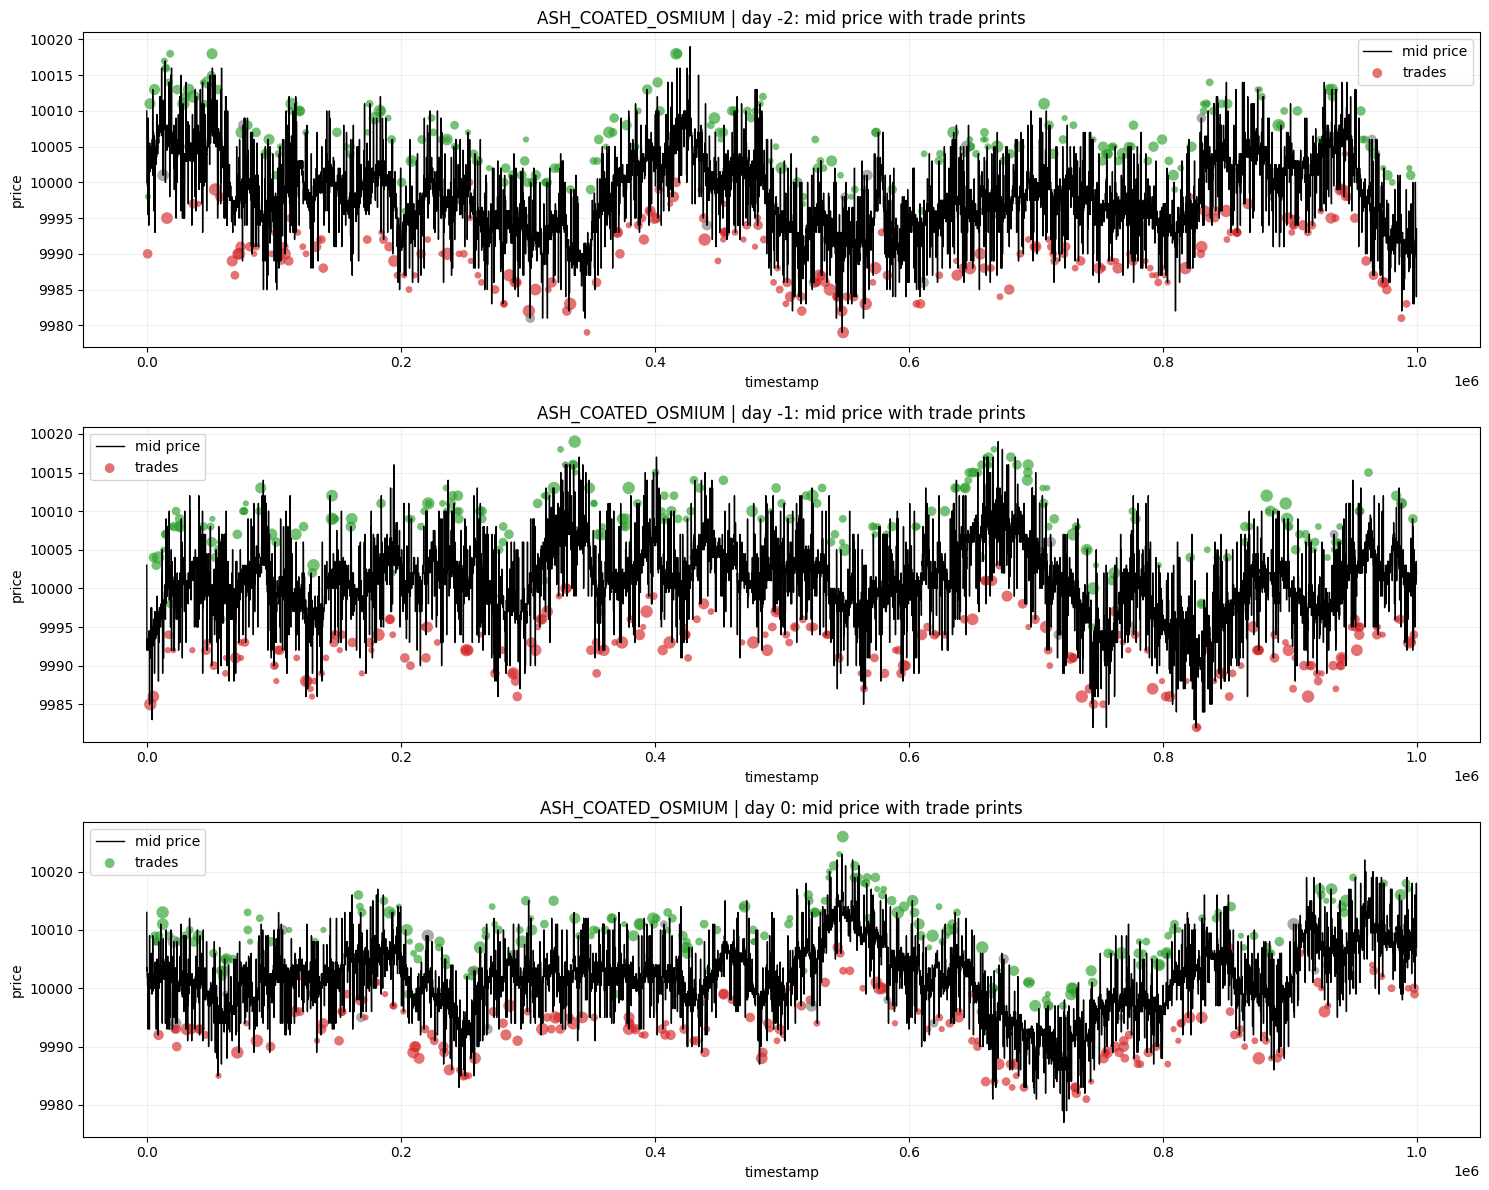

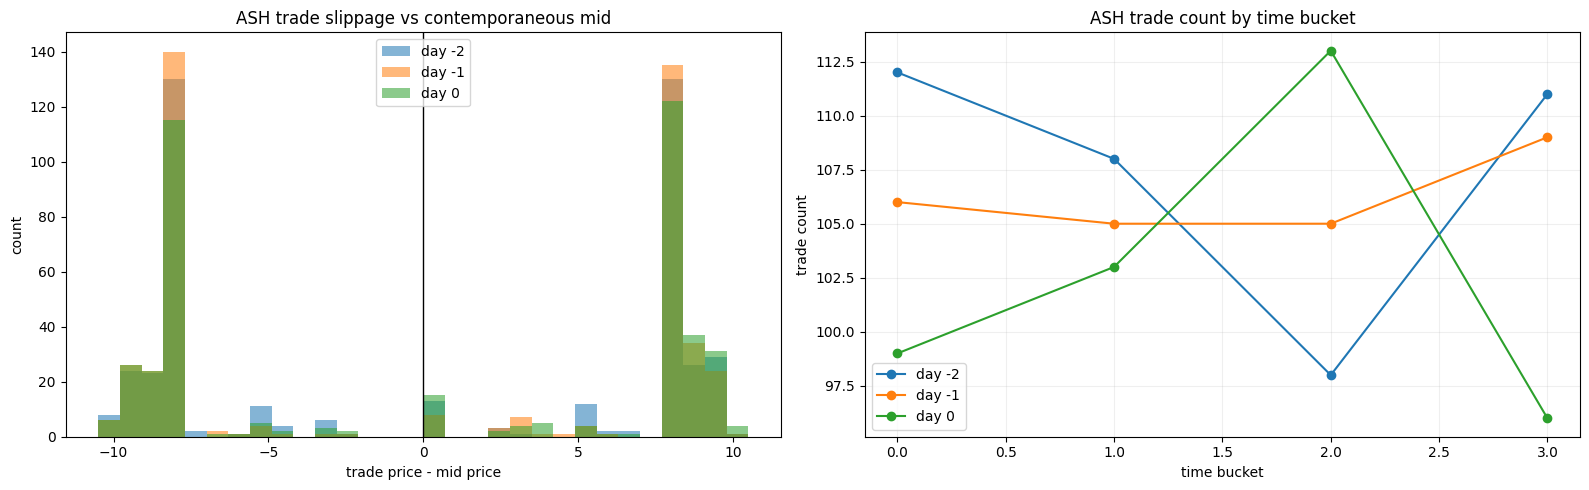

In [16]:
days = sorted(ash_price_prod["day"].dropna().unique().tolist())
fig, axes = plt.subplots(len(days), 1, figsize=(15, 4 * len(days)), sharex=False)
if len(days) == 1:
    axes = [axes]

for ax, day in zip(axes, days):
    price_day = ash_price_prod[ash_price_prod["day"] == day]
    trade_day = ash_trade_ctx[ash_trade_ctx["day"] == day]

    ax.plot(price_day["timestamp"], price_day["mid_price"], color="black", linewidth=1.0, label="mid price")
    if not trade_day.empty:
        colors = np.where(trade_day["trade_side_est"] == "buy_aggressive", "tab:green", np.where(trade_day["trade_side_est"] == "sell_aggressive", "tab:red", "tab:gray"))
        sizes = np.clip(trade_day["quantity"].abs() * 8, 20, 220)
        ax.scatter(trade_day["timestamp"], trade_day["price"], s=sizes, c=colors, alpha=0.65, edgecolors="none", label="trades")
    ax.set_title(f"ASH_COATED_OSMIUM | day {day}: mid price with trade prints")
    ax.set_xlabel("timestamp")
    ax.set_ylabel("price")
    ax.grid(alpha=0.2)
    ax.legend(loc="best")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for day in days:
    slippage_day = ash_trade_ctx[ash_trade_ctx["day"] == day]["slippage_vs_mid"].dropna()
    axes[0].hist(slippage_day, bins=30, alpha=0.55, label=f"day {day}")
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_title("ASH trade slippage vs contemporaneous mid")
axes[0].set_xlabel("trade price - mid price")
axes[0].set_ylabel("count")
axes[0].legend()

time_counts = ash_trade_ctx.groupby(["day", "time_bucket"]).size().reset_index(name="trade_count")
for day in days:
    subset = time_counts[time_counts["day"] == day]
    axes[1].plot(subset["time_bucket"], subset["trade_count"], marker="o", label=f"day {day}")
axes[1].set_title("ASH trade count by time bucket")
axes[1].set_xlabel("time bucket")
axes[1].set_ylabel("trade count")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()